# Homework 6 - DSCI 552

## 1. Tree-Based Methods

### 1(a) APS Failure Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    accuracy_score
)
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline

from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.ensemble import BalancedRandomForestClassifier

In [2]:
train_df = pd.read_csv(
    "data/aps_failure_training_set.csv",
    skiprows=20,
    na_values="na"
)

test_df = pd.read_csv(
    "data/aps_failure_test_set.csv",
    skiprows=20,
    na_values="na"
)

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)

display(train_df.head())

Training shape: (60000, 171)
Test shape: (16000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


### 1(b)i Missing Value Imputation

In [3]:
X_train = train_df.drop(columns=["class"])
X_test = test_df.drop(columns=["class"])

y_train = train_df["class"].map({"neg": 0, "pos": 1})
y_test = test_df["class"].map({"neg": 0, "pos": 1})

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)

print("Training missing values:", X_train.isna().sum().sum())
print("Test missing values:", X_test.isna().sum().sum())
print(f"Training rows with at least one missing value: {X_train.isna().any(axis=1).mean():.2%}")

Training features: (60000, 170)
Test features: (16000, 170)
Training missing values: 850015
Test missing values: 228680
Training rows with at least one missing value: 99.02%


In [4]:
# Training set is filled with training medians.
# Test set is filled with its own medians (footnote 1 of the assignment).
train_imputer = SimpleImputer(strategy="median")
X_train_imputed = pd.DataFrame(
    train_imputer.fit_transform(X_train),
    columns=X_train.columns
)

test_imputer = SimpleImputer(strategy="median")
X_test_imputed = pd.DataFrame(
    test_imputer.fit_transform(X_test),
    columns=X_test.columns
)

print("Missing values after imputation:")
print("Training:", X_train_imputed.isna().sum().sum())
print("Test:", X_test_imputed.isna().sum().sum())
print("Shapes:", X_train_imputed.shape, X_test_imputed.shape)

Missing values after imputation:
Training: 0
Test: 0
Shapes: (60000, 170) (16000, 170)


**Missing value imputation**

Common ways of dealing with missing data are: dropping the incomplete rows or columns, filling with the mean / median / mode, KNN imputation, iterative (regression-based, e.g. MICE) imputation, and adding an indicator variable that marks which values were missing. Dropping rows is not an option here, since about 99% of the training rows have at least one missing value.

I used median imputation. The features are very skewed, and the median is not pulled around by the few extreme values the way the mean is. Following footnote 1 of the assignment, the training set is filled with the training medians and the test set is filled with medians computed from the test set itself.

### 1(b)ii Coefficient of Variation

In [5]:
# Coefficient of variation for all 170 features (computed after imputation)
means = X_train_imputed.mean()
stds = X_train_imputed.std(ddof=1)

cv_values = stds / means.replace(0, np.nan)

cv_df = pd.DataFrame({
    "Feature": X_train_imputed.columns,
    "CV": cv_values.values
})

cv_df = cv_df.sort_values(by="CV", ascending=False)

display(cv_df)

,Feature,CV
91,cf_000,244.887517
109,co_000,244.507385
3,ad_000,244.322816
122,cs_009,237.930554
136,dh_000,123.216097
...,...,...
75,bo_000,0.792383
76,bp_000,0.753392
77,bq_000,0.718534
78,br_000,0.689112


In [6]:
print("Number of features:", len(cv_df))
print("Number of undefined CV values:", cv_df["CV"].isna().sum())
print("Constant features:", stds[stds == 0].index.tolist())

print("\nTop 13 features with highest CV:")
display(cv_df.head(13))

Number of features: 170
Number of undefined CV values: 0
Constant features: ['cd_000']

Top 13 features with highest CV:


,Feature,CV
91,cf_000,244.887517
109,co_000,244.507385
3,ad_000,244.322816
122,cs_009,237.930554
136,dh_000,123.216097
138,dj_000,117.494225
6,ag_000,92.917755
27,as_000,87.332500
41,ay_009,84.733735
19,ak_000,80.424975


$CV = s/m$ was computed for every feature (after imputation), where $s$ is the sample standard deviation and $m$ the sample mean.

`cd_000` is a constant feature ($s = 0$), so its CV is 0 and it carries no information. The CVs are very spread out: the top four features (`cf_000`, `co_000`, `ad_000`, `cs_009`) have CV above 200, which means they are mostly small values with a few enormous ones.

### 1(b)iii Correlation Matrix

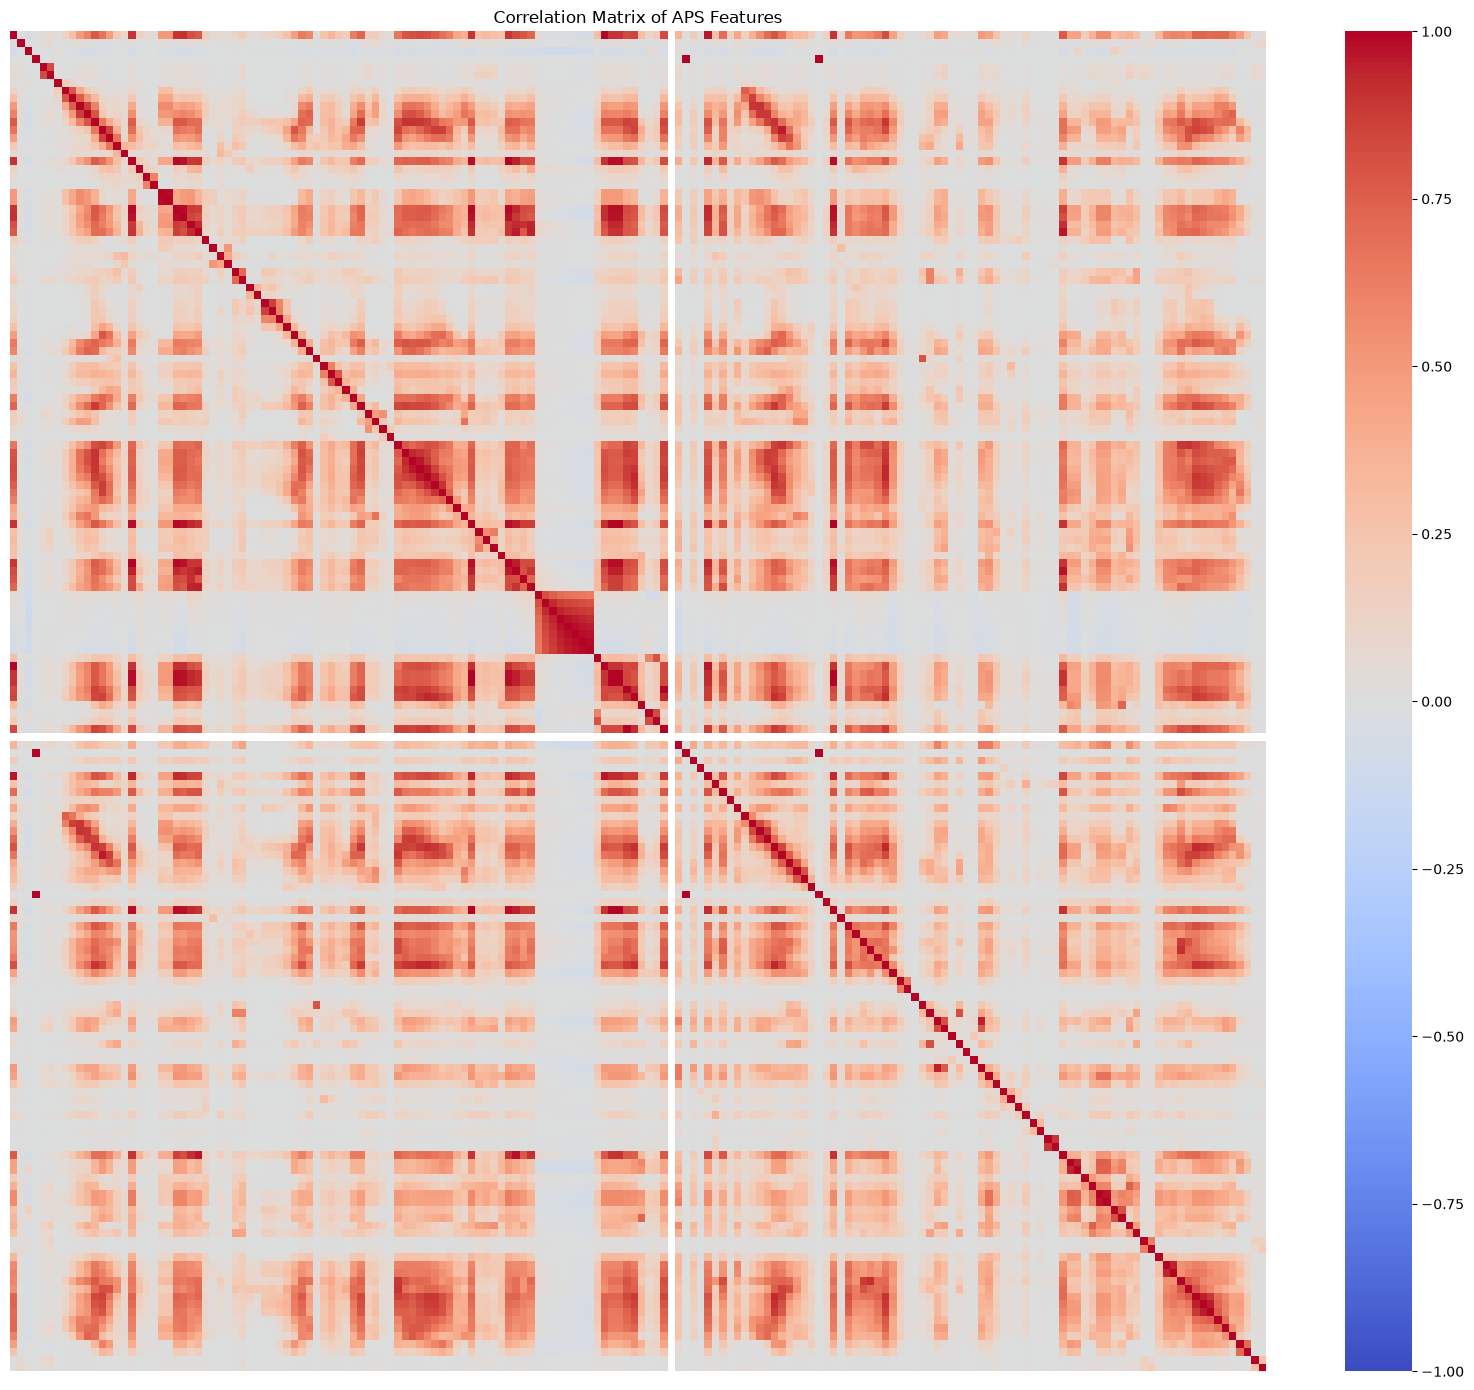

In [7]:
# Calculate the correlation matrix of all 170 features
corr_matrix = X_train_imputed.corr()

# Plot correlation heatmap
plt.figure(figsize=(16, 14))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    xticklabels=False,
    yticklabels=False
)

plt.title("Correlation Matrix of APS Features")
plt.tight_layout()
plt.show()

In [8]:
# Look at the strongest pairwise correlations
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1)
)
pairs = upper.stack()

print("Features with undefined correlation:",
      corr_matrix.columns[corr_matrix.isna().all()].tolist())
print("Pairs with |r| > 0.9:", (pairs.abs() > 0.9).sum())
print("Pairs with |r| > 0.7:", (pairs.abs() > 0.7).sum())
print("Most negative correlation:", round(pairs.min(), 4))

display(pairs.sort_values(ascending=False).head(10))

Features with undefined correlation: ['cd_000']
Pairs with |r| > 0.9: 130
Pairs with |r| > 0.7: 772
Most negative correlation: -0.1056


bv_000  cq_000    1.000000
bu_000  cq_000    1.000000
        bv_000    1.000000
cf_000  co_000    1.000000
ad_000  cf_000    1.000000
        co_000    1.000000
aa_000  bt_000    0.998774
ah_000  bg_000    0.997745
bb_000  bv_000    0.996258
        bu_000    0.996258
dtype: float64

`cd_000` is constant, so its correlations are undefined and its row/column in the heatmap is blank.

Most of the matrix is close to 0, but there are clear blocks of strongly correlated features: 130 pairs have $|r| > 0.9$ and 772 pairs have $|r| > 0.7$. Some features are practically duplicates of each other, e.g. `cf_000` / `co_000` / `ad_000` and `bu_000` / `bv_000` / `cq_000` ($r \approx 1$). Negative correlations are all weak (the most negative is about $-0.11$). So the feature set is quite redundant. This is not a big problem for tree-based models, but it would be for an unregularized linear model.

### 1(b)iv Scatter Plots and Box Plots

In [9]:
# Select the 13 features with the highest CV
top_features = (
    cv_df.dropna(subset=["CV"])
    .head(13)["Feature"]
    .tolist()
)

print("Top 13 features with highest CV:")
print(top_features)

Top 13 features with highest CV:
['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


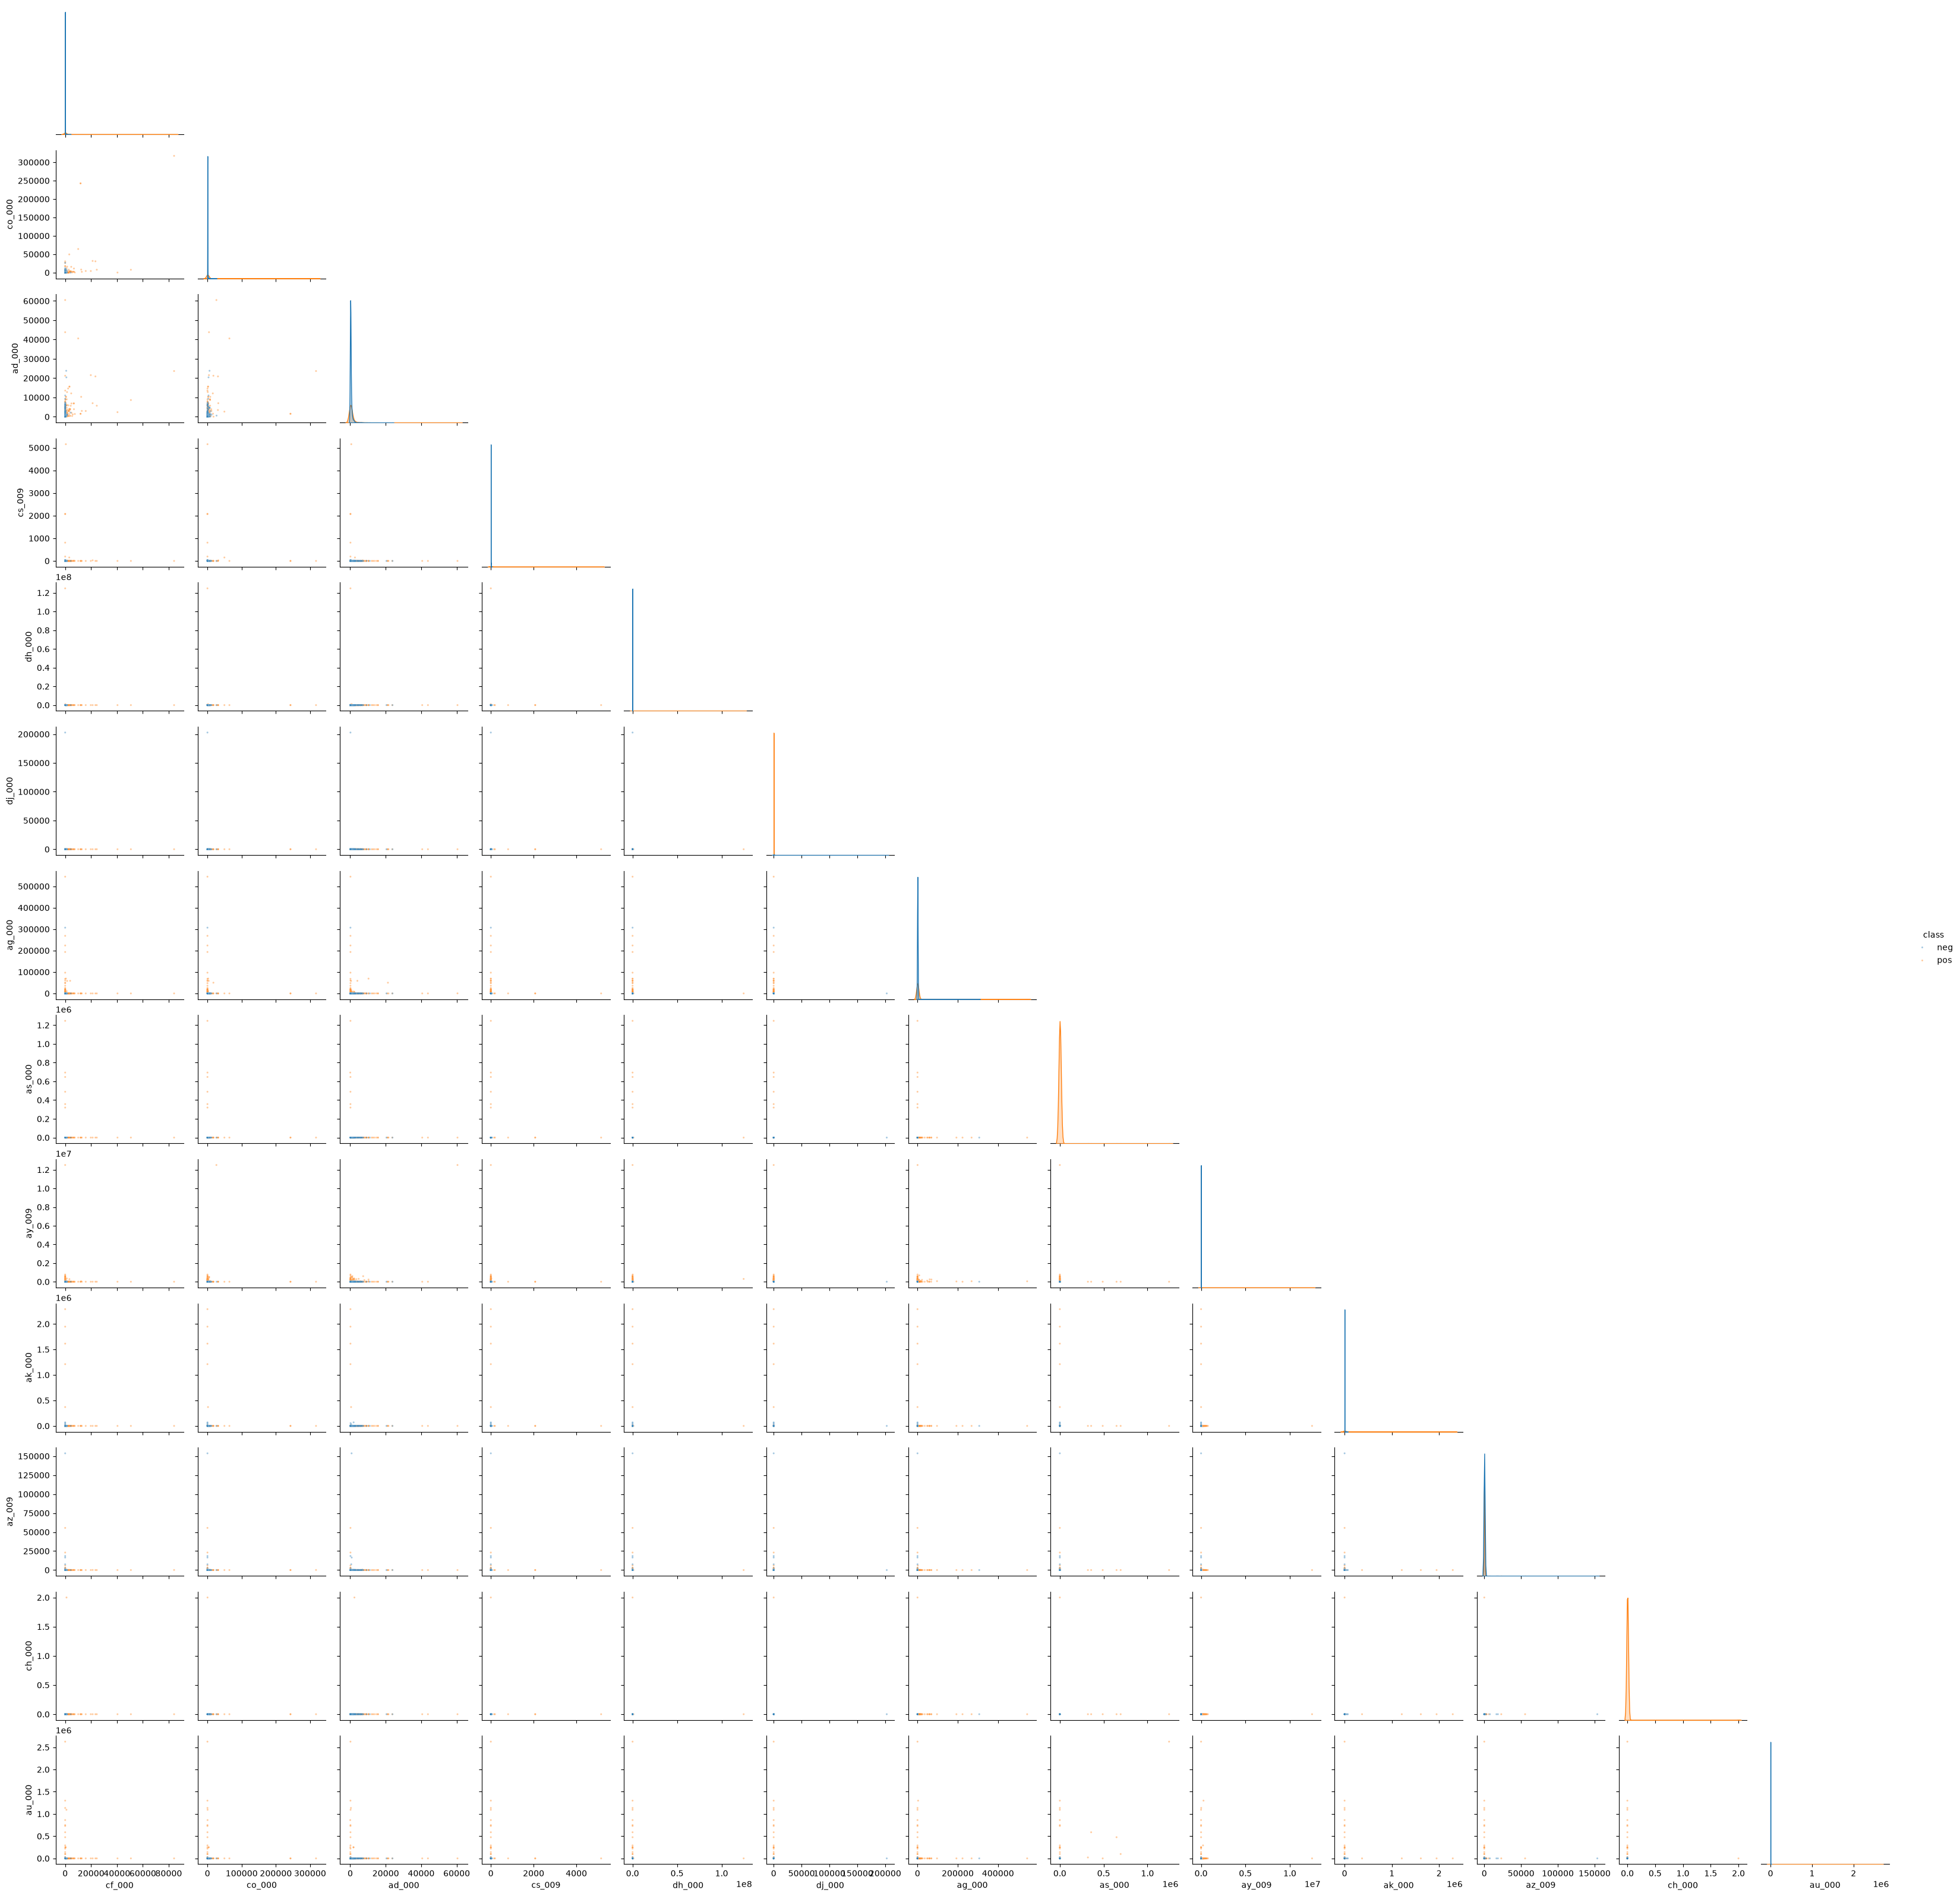

In [10]:
# Keep all 1,000 positives and sample 2,000 negatives so the minority class is visible
plot_data = X_train_imputed[top_features].copy()
plot_data["class"] = y_train.map({0: "neg", 1: "pos"})

plot_data = pd.concat([
    plot_data[plot_data["class"] == "pos"],
    plot_data[plot_data["class"] == "neg"].sample(n=2000, random_state=42)
])

# Scatter plot matrix colored by class (similar to ISLR Figure 4.1)
sns.pairplot(
    plot_data,
    hue="class",
    hue_order=["neg", "pos"],
    corner=True,
    plot_kws={"s": 5, "alpha": 0.4}
)

plt.show()

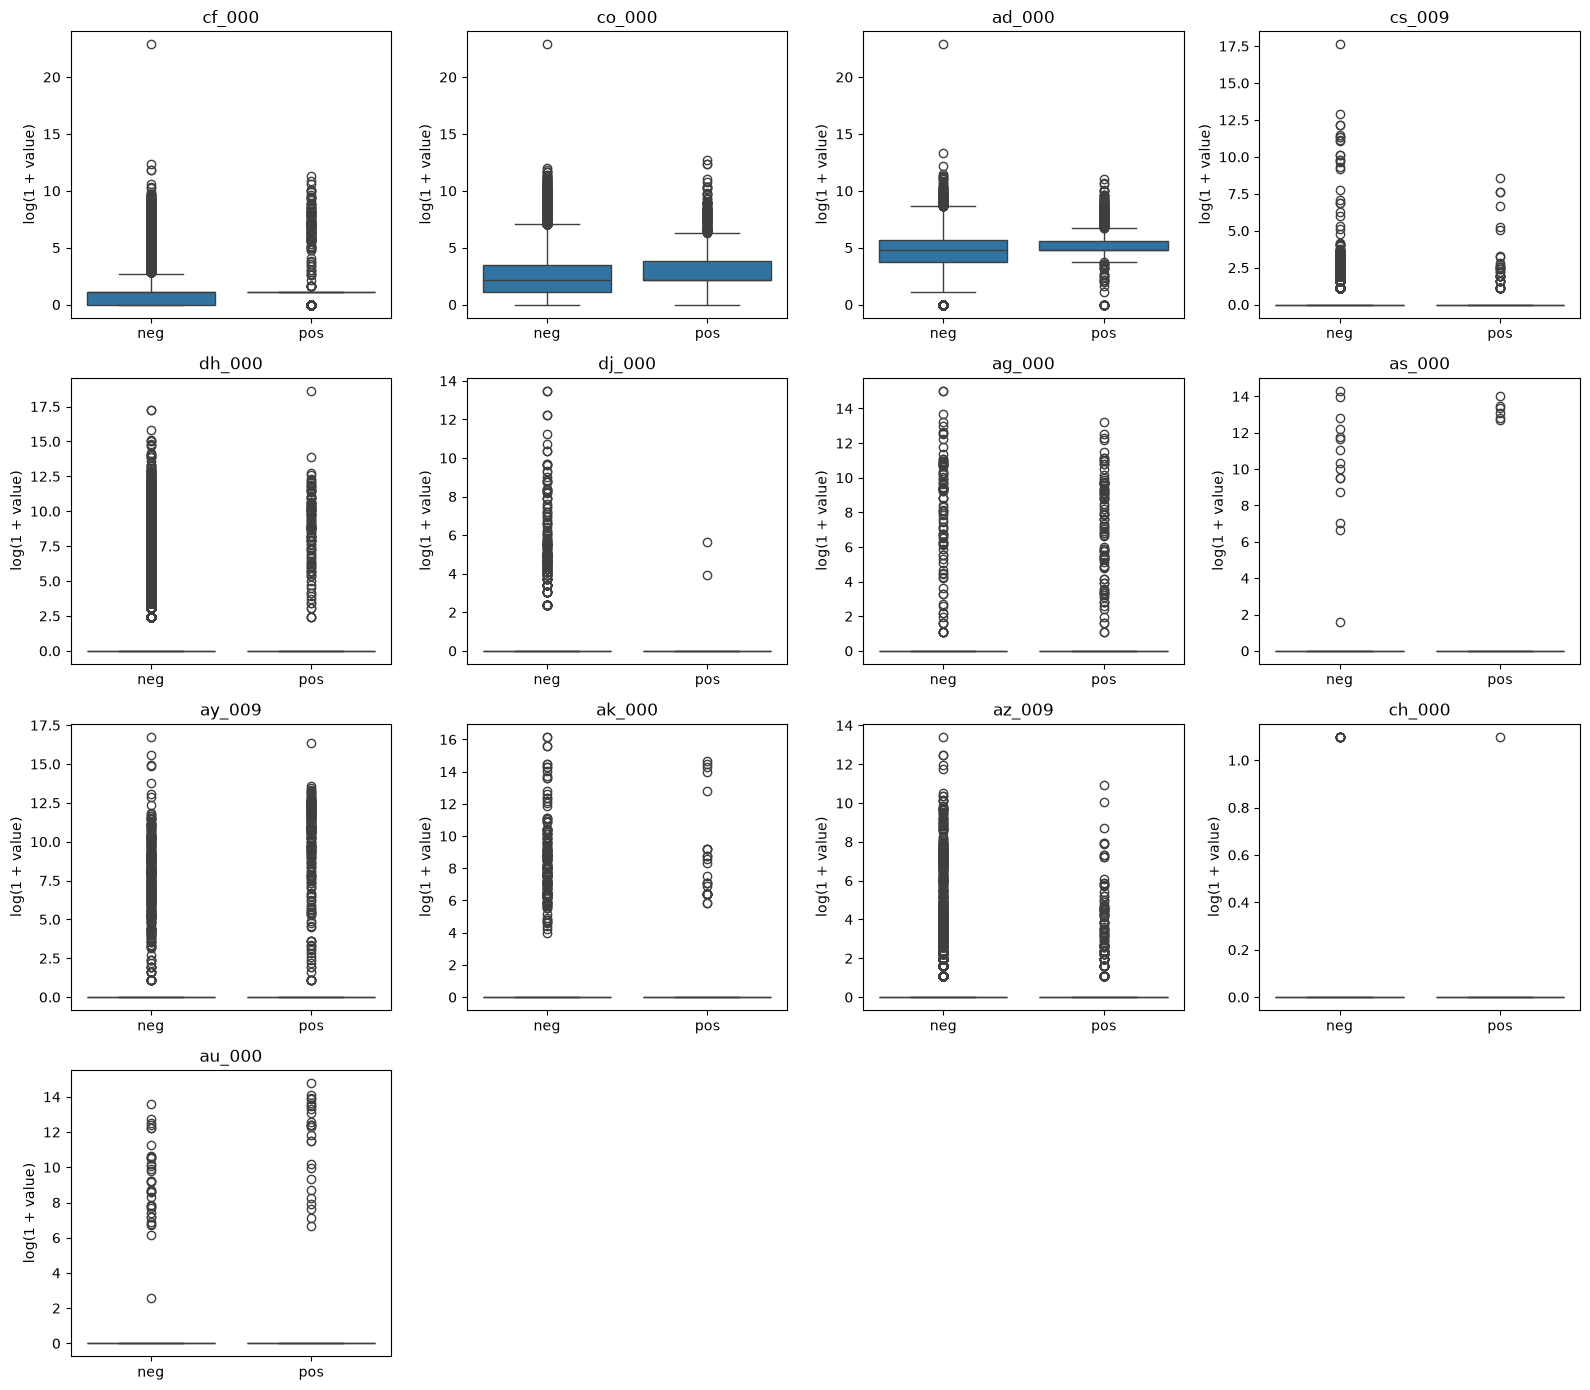

In [11]:
# Box plots of each feature split by class.
# The raw values are extremely skewed, so they are shown on a log(1 + x) scale.
class_labels = y_train.map({0: "neg", 1: "pos"})

fig, axes = plt.subplots(4, 4, figsize=(16, 14))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    sns.boxplot(
        x=class_labels,
        y=np.log1p(X_train_imputed[feature]),
        order=["neg", "pos"],
        ax=axes[i]
    )
    axes[i].set_title(feature)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("log(1 + value)")

for i in range(len(top_features), len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [12]:
# Compare the two classes on these features (raw training data, before imputation)
raw_top = X_train[top_features]
neg, pos = raw_top[y_train == 0], raw_top[y_train == 1]

class_summary = pd.concat({
    "missing (neg)": neg.isna().mean(),
    "missing (pos)": pos.isna().mean(),
    "nonzero (neg)": (neg > 0).mean(),
    "nonzero (pos)": (pos > 0).mean(),
    "mean (neg)": neg.mean(),
    "mean (pos)": pos.mean()
}, axis=1)

display(class_summary.round(3))

,missing (neg),missing (pos),nonzero (neg),nonzero (pos),mean (neg),mean (pos)
cf_000,0.241,0.645,0.399,0.151,191718.356,1429.527
co_000,0.241,0.645,0.543,0.319,191993.428,4080.265
ad_000,0.241,0.645,0.725,0.328,192113.745,2262.214
cs_009,0.011,0.004,0.048,0.052,792.318,10.771
dh_000,0.059,0.524,0.116,0.119,2416.466,271861.155
dj_000,0.059,0.524,0.003,0.002,40.275,0.693
ag_000,0.011,0.004,0.002,0.097,188.541,2159.926
as_000,0.010,0.042,0.000,0.006,64.549,3918.547
ay_009,0.011,0.005,0.006,0.207,619.552,33001.254
ak_000,0.066,0.532,0.006,0.031,851.811,16020.521


For the scatter plot matrix I used all 1,000 positives plus 2,000 randomly sampled negatives, otherwise the positive class is almost invisible. The box plots use the full training set, split by class, on a $\log(1+x)$ scale because the raw values are too skewed to read.

Some differences between the classes do show up:

- For `ag_000`, `ay_009`, `az_009` and `au_000`, almost all negatives are exactly 0, while a noticeable share of positives are nonzero (e.g. 20.7% vs 0.6% for `ay_009`).
- `dh_000` and `ak_000` have much larger means in the positive class.
- `cf_000`, `co_000` and `ad_000` look like the same variable in the scatter plots, which agrees with the correlation matrix.
- About 65% of the positives are missing `cf_000`, `co_000`, `ad_000` and `ch_000` (vs 24% of negatives), so after imputation many positives sit exactly at the median. That is why the class medians of these features are identical.

**Can we draw conclusions about significance from the scatter plots alone?** No. The plots only show marginal and pairwise patterns, the two classes overlap a lot, and the scale is dominated by a few outliers. Whether a feature is statistically significant, or useful for prediction, has to be checked with a test or a model (for example feature importance, or comparing performance with and without the feature).

### 1(b)v Class Imbalance Analysis

In [13]:
# Count positive and negative observations
class_counts = y_train.value_counts()
class_percentages = y_train.value_counts(normalize=True) * 100

print("Class counts:")
print(class_counts)

print("\nClass percentages:")
print(class_percentages)

Class counts:
class
0    59000
1     1000
Name: count, dtype: int64

Class percentages:
class
0    98.333333
1     1.666667
Name: proportion, dtype: float64


The training set has 59,000 negatives and 1,000 positives, so only about 1.7% of the data is positive. The data set is heavily imbalanced: a classifier that always predicts "neg" would already get 98.3% accuracy, so accuracy on its own is not a very informative metric here.

### 1(c) Random Forest without Class Balancing

In [14]:
rf = RandomForestClassifier(
    n_estimators=200,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_imputed, y_train);

In [15]:
def evaluate_model(model, X, y, title):
    y_pred = model.predict(X)
    y_prob = model.predict_proba(X)[:, 1]

    cm = confusion_matrix(y, y_pred)
    auc = roc_auc_score(y, y_prob)
    error = 1 - accuracy_score(y, y_pred)

    print(f"\n{title}")
    print("Confusion Matrix:\n", cm)
    print(f"AUC: {auc:.6f}")
    print(f"Misclassification Rate: {error:.6f}")

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Negative", "Positive"]
    ).plot(cmap="Blues")

    plt.title(title + " Confusion Matrix")
    plt.show()

    fpr, tpr, _ = roc_curve(y, y_prob)

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"AUC = {auc:.4f}")
    plt.plot([0, 1], [0, 1], "k--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(title + " ROC Curve")
    plt.legend()
    plt.show()

    return error


Random Forest Training
Confusion Matrix:
 [[59000     0]
 [    0  1000]]
AUC: 1.000000
Misclassification Rate: 0.000000


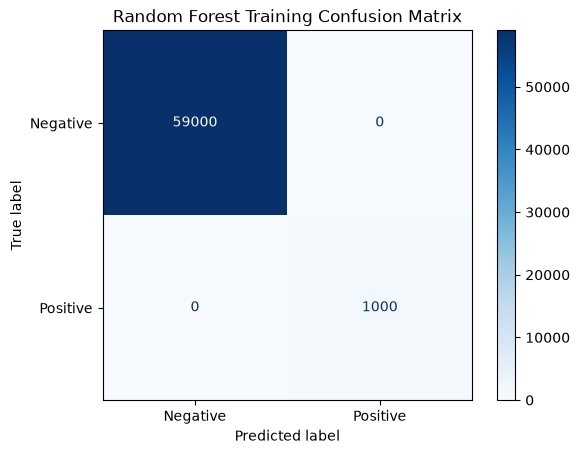

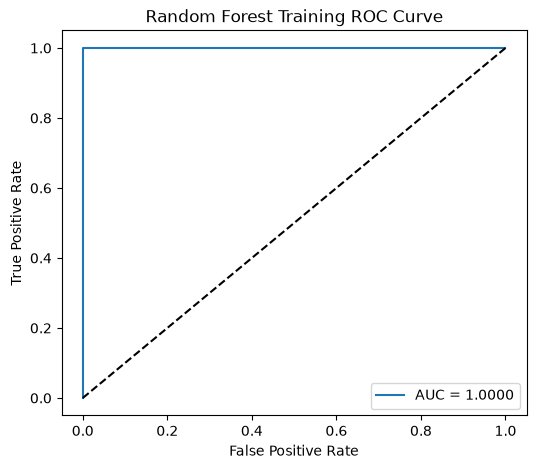

In [16]:
rf_train_error = evaluate_model(
    rf,
    X_train_imputed,
    y_train,
    "Random Forest Training"
)


Random Forest Test
Confusion Matrix:
 [[15609    16]
 [  104   271]]
AUC: 0.994355
Misclassification Rate: 0.007500


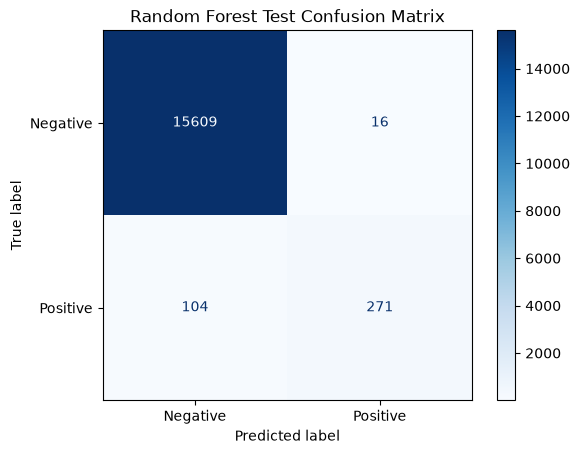

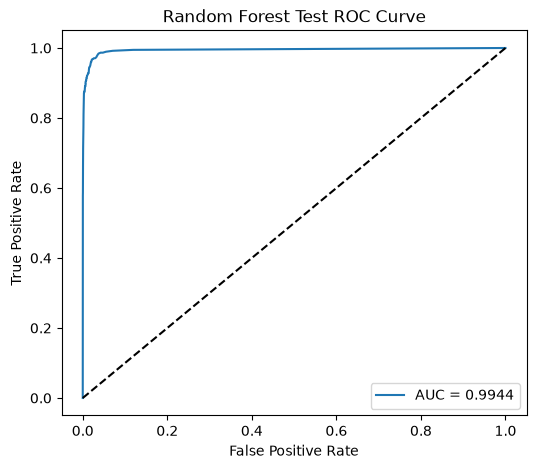

In [17]:
rf_test_error = evaluate_model(
    rf,
    X_test_imputed,
    y_test,
    "Random Forest Test"
)

In [18]:
oob_error = 1 - rf.oob_score_

print(f"OOB Error: {oob_error:.6f}")
print(f"Test Error: {rf_test_error:.6f}")
print(f"Difference: {abs(oob_error - rf_test_error):.6f}")

OOB Error: 0.005900
Test Error: 0.007500
Difference: 0.001600


Random forest with 200 trees, no compensation for class imbalance (confusion matrices are [[TN, FP], [FN, TP]]):

| | Training | Test |
|---|---|---|
| Confusion matrix | [[59000, 0], [0, 1000]] | [[15609, 16], [104, 271]] |
| AUC | 1.0000 | 0.9944 |
| Misclassification rate | 0.0000 | 0.0075 |

The training error is 0. This is expected because the trees are grown until the leaves are pure, so it doesn't say much about how the model generalizes.

On the test set the overall error is low (0.75%), but 104 of the 375 failures are missed, so recall on the positive class is only 72%. Almost all of the errors come from the minority class.

The OOB error is 0.0059 and the test error is 0.0075. They are close, so the OOB estimate is a reasonable (slightly optimistic) estimate of the test error, and we got it without needing a separate validation set.

### 1(d) Random Forest with Class Balancing

In [19]:
# Random Forest with class weights recomputed on each bootstrap sample
rf_balanced = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced_subsample",
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

rf_balanced.fit(X_train_imputed, y_train);


Balanced Random Forest Training
Confusion Matrix:
 [[59000     0]
 [    0  1000]]
AUC: 1.000000
Misclassification Rate: 0.000000


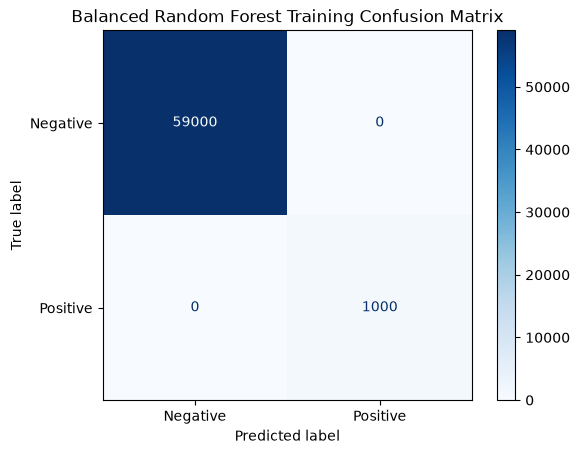

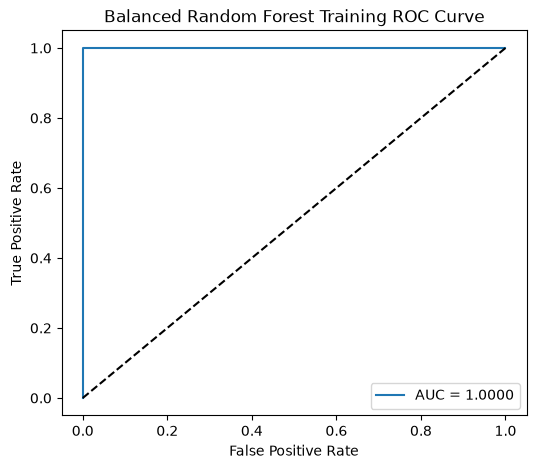

In [20]:
rf_balanced_train_error = evaluate_model(
    rf_balanced,
    X_train_imputed,
    y_train,
    "Balanced Random Forest Training"
)


Balanced Random Forest Test
Confusion Matrix:
 [[15611    14]
 [  162   213]]
AUC: 0.991921
Misclassification Rate: 0.011000


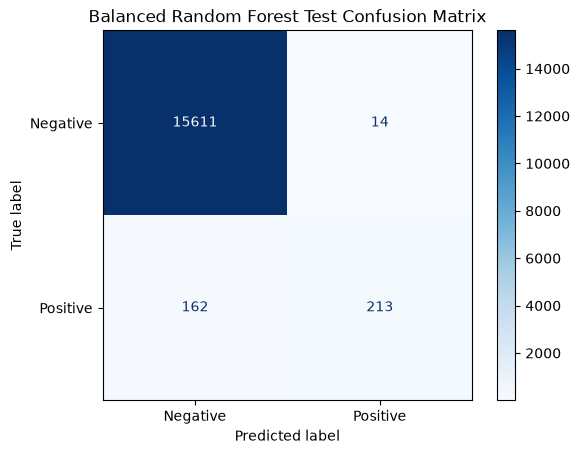

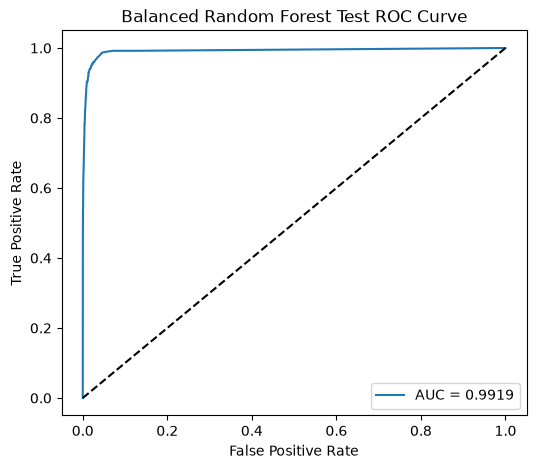

In [21]:
rf_balanced_test_error = evaluate_model(
    rf_balanced,
    X_test_imputed,
    y_test,
    "Balanced Random Forest Test"
)

In [22]:
balanced_oob_error = 1 - rf_balanced.oob_score_

print(f"Balanced RF OOB Error: {balanced_oob_error:.6f}")
print(f"Balanced RF Test Error: {rf_balanced_test_error:.6f}")
print(f"Difference: {abs(balanced_oob_error - rf_balanced_test_error):.6f}")

Balanced RF OOB Error: 0.007700
Balanced RF Test Error: 0.011000
Difference: 0.003300



Balanced Random Forest (undersampling) Training
Confusion Matrix:
 [[56416  2584]
 [    0  1000]]
AUC: 0.998186
Misclassification Rate: 0.043067


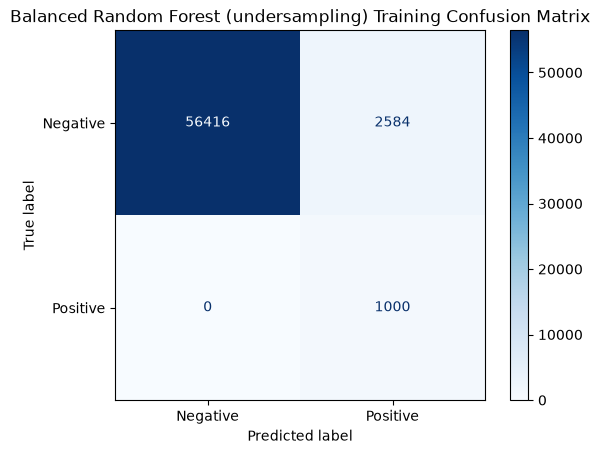

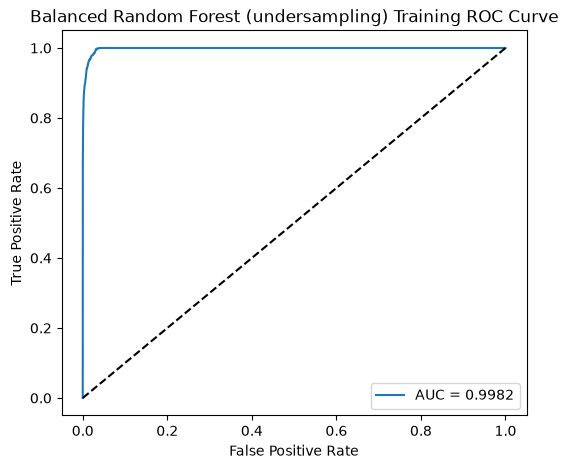

In [23]:
# Second approach: Balanced Random Forest (each tree is grown on a
# class-balanced sample obtained by undersampling the negative class)
brf = BalancedRandomForestClassifier(
    n_estimators=200,
    sampling_strategy="all",
    replacement=True,
    bootstrap=False,
    random_state=42,
    n_jobs=-1
)

brf.fit(X_train_imputed, y_train)

brf_train_error = evaluate_model(
    brf,
    X_train_imputed,
    y_train,
    "Balanced Random Forest (undersampling) Training"
)


Balanced Random Forest (undersampling) Test
Confusion Matrix:
 [[14968   657]
 [    8   367]]
AUC: 0.992730
Misclassification Rate: 0.041562


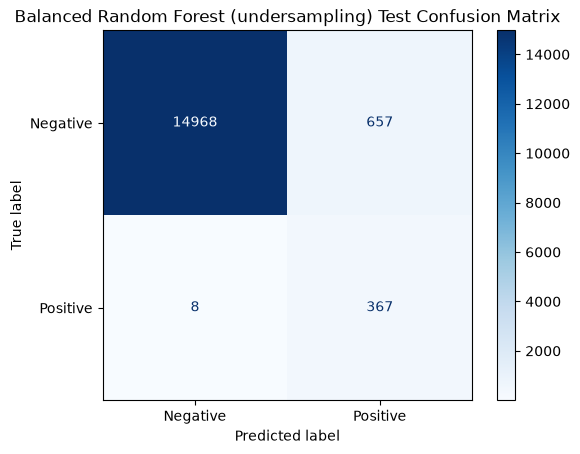

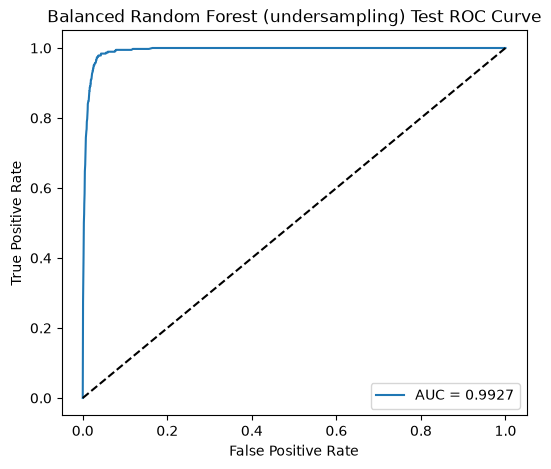

In [24]:
brf_test_error = evaluate_model(
    brf,
    X_test_imputed,
    y_test,
    "Balanced Random Forest (undersampling) Test"
)

In [25]:
# Compare the three Random Forest variants on the test set
def test_summary(model, X, y):
    cm = confusion_matrix(y, model.predict(X))
    return {
        "Test Error": 1 - accuracy_score(y, model.predict(X)),
        "Test AUC": roc_auc_score(y, model.predict_proba(X)[:, 1]),
        "False Positives": cm[0, 1],
        "False Negatives": cm[1, 0],
        "Positive Recall": cm[1, 1] / cm[1].sum(),
        # cost defined in the APS data description: 10 per false alarm, 500 per missed failure
        "APS Cost": 10 * cm[0, 1] + 500 * cm[1, 0]
    }

comparison_df = pd.DataFrame([
    {"Model": "RF (no compensation)", "OOB Error": oob_error,
     **test_summary(rf, X_test_imputed, y_test)},
    {"Model": "RF (balanced_subsample)", "OOB Error": balanced_oob_error,
     **test_summary(rf_balanced, X_test_imputed, y_test)},
    {"Model": "Balanced RF (undersampling)", "OOB Error": np.nan,
     **test_summary(brf, X_test_imputed, y_test)}
])

display(comparison_df.round(6))

,Model,OOB Error,Test Error,Test AUC,False Positives,False Negatives,Positive Recall,APS Cost
0,RF (no compensation),0.0059,0.007500,0.994355,16,104,0.722667,52160
1,RF (balanced_subsample),0.0077,0.011000,0.991921,14,162,0.568000,81140
2,Balanced RF (undersampling),NaN,0.041562,0.992730,657,8,0.978667,10570


**How class imbalance is handled in random forests**

1. *Cost-sensitive learning*: give the minority class a larger weight in the split criterion and in the leaf votes. In scikit-learn this is `class_weight="balanced"` or `"balanced_subsample"` (weights recomputed on each bootstrap sample).
2. *Resampling for each tree*: grow each tree on a class-balanced sample, either by undersampling the majority class (Balanced Random Forest, Chen, Liaw & Breiman 2004) or by oversampling the minority class.
3. *Moving the decision threshold* below 0.5 instead of changing the training.

I tried the first two: `RandomForestClassifier(class_weight="balanced_subsample")` and imbalanced-learn's `BalancedRandomForestClassifier`, which undersamples the negatives for every tree.

| | RF (no compensation) | RF (balanced_subsample) | Balanced RF (undersampling) |
|---|---|---|---|
| Train confusion matrix | [[59000, 0], [0, 1000]] | [[59000, 0], [0, 1000]] | [[56416, 2584], [0, 1000]] |
| Train AUC / error | 1.0000 / 0.0000 | 1.0000 / 0.0000 | 0.9982 / 0.0431 |
| Test confusion matrix | [[15609, 16], [104, 271]] | [[15611, 14], [162, 213]] | [[14968, 657], [8, 367]] |
| Test AUC | 0.9944 | 0.9919 | 0.9927 |
| Test error | 0.0075 | 0.0110 | 0.0416 |
| OOB error | 0.0059 | 0.0077 | – |
| Positive recall (test) | 72.3% | 56.8% | 97.9% |
| APS cost (10·FP + 500·FN) | 52,160 | 81,140 | 10,570 |

`balanced_subsample` did not help. The test error went up from 0.0075 to 0.0110 and recall actually dropped from 72% to 57%. My guess is that since the trees are fully grown, nearly every leaf is pure, so the class weights hardly change the votes. They mainly change which splits get chosen, and that made the trees slightly worse here. Its OOB error (0.0077) is again a bit lower than its test error (0.0110).

The Balanced Random Forest behaves very differently. It catches 367 of the 375 failures (only 8 false negatives), but produces 657 false alarms, so its error rate is the highest of the three (0.0416). The AUCs of all three models are about the same (0.992–0.994). This means they rank the trucks in roughly the same order; what changes is mostly where the effective decision threshold ends up. No OOB error is reported for it because each tree is trained on an undersampled set (`bootstrap=False`), so there is no standard OOB sample.

Which model is better depends on what an error costs. By misclassification rate the plain RF wins. But in the APS problem a missed failure costs 50 times more than an unnecessary check, and with that cost the Balanced RF is by far the cheapest (10,570 vs 52,160).

### 1(e) XGBoost and Model Trees

In [26]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Imputer is part of the pipeline, so in every CV fold the medians
# are computed from the training part of that fold only
xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("xgb", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        n_estimators=200,
        max_depth=4,
        learning_rate=0.1,
        tree_method="hist",
        random_state=42,
        n_jobs=4
    ))
])

In [27]:
# reg_alpha is the L1 penalty in XGBoost
param_grid = {
    "xgb__reg_alpha": [0, 0.001, 0.01, 0.05, 0.1, 0.5, 1, 10]
}

grid_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=param_grid,
    cv=skf,
    scoring="accuracy",
    n_jobs=1
)

grid_search.fit(X_train, y_train)

display(
    pd.DataFrame(grid_search.cv_results_)[
        ["param_xgb__reg_alpha", "mean_test_score", "std_test_score"]
    ]
)

print("Best alpha:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)
print("CV Error:", 1 - grid_search.best_score_)

,param_xgb__reg_alpha,mean_test_score,std_test_score
0,0.000,0.994217,0.000634
1,0.001,0.994083,0.000514
2,0.010,0.994233,0.000295
3,0.050,0.994250,0.000508
4,0.100,0.994300,0.000430
5,0.500,0.994333,0.000506
6,1.000,0.994133,0.000476
7,10.000,0.993067,0.000755


Best alpha: {'xgb__reg_alpha': 0.5}
Best CV Accuracy: 0.9943333333333333
CV Error: 0.005666666666666709



XGBoost Training
Confusion Matrix:
 [[58999     1]
 [   47   953]]
AUC: 0.999724
Misclassification Rate: 0.000800


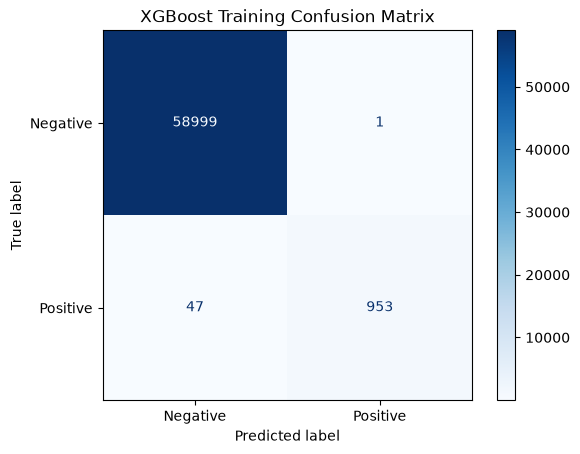

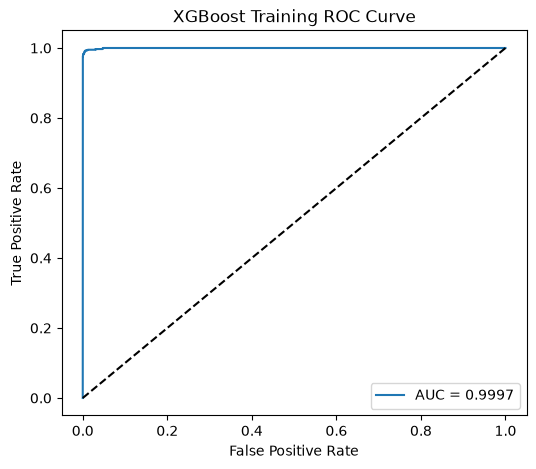

In [28]:
# Evaluate XGBoost on training set
# (the final pipeline was refitted on the full training set, so it fills with training medians)
best_xgb = grid_search.best_estimator_

xgb_train_error = evaluate_model(
    best_xgb,
    X_train,
    y_train,
    "XGBoost Training"
)


XGBoost Test
Confusion Matrix:
 [[15610    15]
 [   88   287]]
AUC: 0.995553
Misclassification Rate: 0.006437


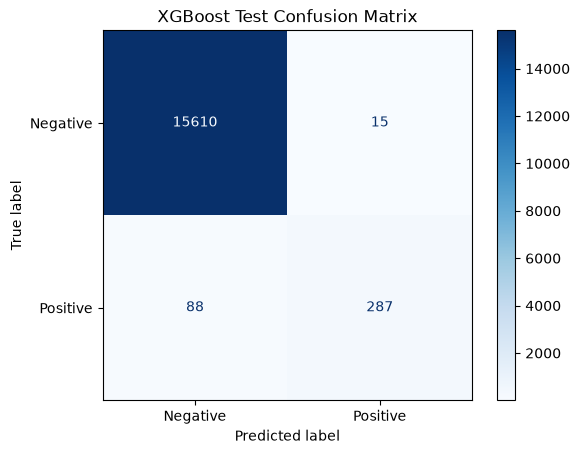

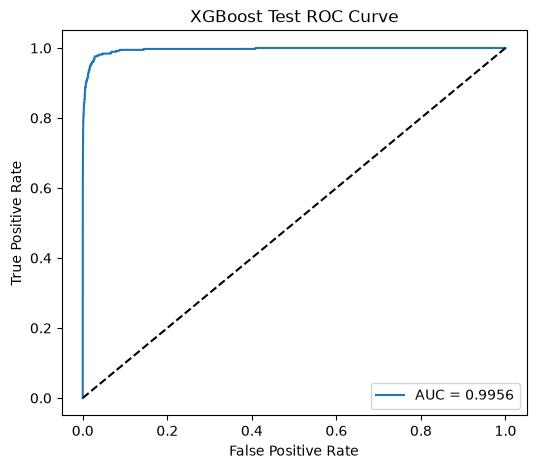

In [29]:
# Evaluate XGBoost on test set
# (the test set is already filled with its own medians, so the pipeline's imputer has nothing to fill)
xgb_test_error = evaluate_model(
    best_xgb,
    X_test_imputed,
    y_test,
    "XGBoost Test"
)

In [30]:
# Compare cross-validation error and test error
xgb_cv_error = 1 - grid_search.best_score_

print(f"Best Alpha: {grid_search.best_params_['xgb__reg_alpha']}")
print(f"CV Error: {xgb_cv_error:.6f}")
print(f"Test Error: {xgb_test_error:.6f}")
print(f"Difference: {abs(xgb_cv_error - xgb_test_error):.6f}")

Best Alpha: 0.5
CV Error: 0.005667
Test Error: 0.006437
Difference: 0.000771


**Model.** Following the assignment, I used XGBoost to fit the model tree: the trees are trained with the logistic loss (`objective="binary:logistic"`) and an L1 penalty $\alpha$ (`reg_alpha`), and $\alpha$ is chosen by cross-validation. (Technically, each split in XGBoost is still on a single feature, and the L1 penalty acts on the leaf weights.)

**Choosing $\alpha$.** I ran 5-fold stratified CV over $\alpha \in \{0, 0.001, 0.01, 0.05, 0.1, 0.5, 1, 10\}$. Median imputation is part of the pipeline, so in each fold the medians come from the training part of that fold only and the validation fold does not leak into the imputation. The best value was $\alpha = 0.5$ (CV accuracy 0.99433, CV error 0.00567). All values with $\alpha \le 1$ are within about 0.00025 of each other, which is less than their standard deviations across folds (0.0003–0.0006), so in practice $\alpha$ hardly matters here. Only $\alpha = 10$ is clearly worse.

| | Training | Test |
|---|---|---|
| Confusion matrix | [[58999, 1], [47, 953]] | [[15610, 15], [88, 287]] |
| AUC | 0.9997 | 0.9956 |
| Misclassification rate | 0.0008 | 0.0064 |

**CV error vs test error.** The 5-fold CV error is 0.00567 and the test error is 0.00644, so CV gives a good estimate. It is slightly optimistic, partly because the same CV scores were used to pick $\alpha$ (nested CV would remove that bias).

Compared with the uncompensated random forest, XGBoost is a little better on the test set: error 0.0064 vs 0.0075, AUC 0.9956 vs 0.9944, and 88 instead of 104 missed failures. It still misses about 23% of the positives.

### 1(f) SMOTE and XGBoost

In [31]:
# Imputation and SMOTE are inside the pipeline, so in every CV fold
# they are fitted on the training part of that fold only
smote_pipeline = ImbPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("smote", SMOTE(random_state=42)),
    ("xgb", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        n_estimators=200,
        max_depth=4,
        learning_rate=0.1,
        tree_method="hist",
        random_state=42,
        n_jobs=4
    ))
])

In [32]:
smote_grid = {
    "xgb__reg_alpha": [0, 0.001, 0.01, 0.05, 0.1, 0.5, 1, 10]
}

smote_search = GridSearchCV(
    estimator=smote_pipeline,
    param_grid=smote_grid,
    cv=skf,
    scoring="accuracy",
    n_jobs=1
)

smote_search.fit(X_train, y_train)

display(
    pd.DataFrame(smote_search.cv_results_)[
        ["param_xgb__reg_alpha", "mean_test_score", "std_test_score"]
    ]
)

print("Best Alpha:", smote_search.best_params_)
print("Best CV Accuracy:", smote_search.best_score_)
print("CV Error:", 1 - smote_search.best_score_)

,param_xgb__reg_alpha,mean_test_score,std_test_score
0,0.000,0.990717,0.000987
1,0.001,0.990783,0.000917
2,0.010,0.990683,0.000777
3,0.050,0.990533,0.000834
4,0.100,0.990600,0.000602
5,0.500,0.990800,0.000584
6,1.000,0.990667,0.000860
7,10.000,0.990000,0.000685


Best Alpha: {'xgb__reg_alpha': 0.5}
Best CV Accuracy: 0.9908000000000001
CV Error: 0.009199999999999875



SMOTE XGBoost Training
Confusion Matrix:
 [[58765   235]
 [   46   954]]
AUC: 0.998958
Misclassification Rate: 0.004683


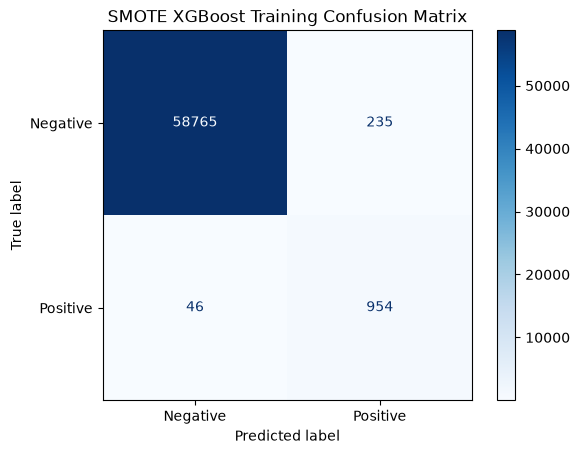

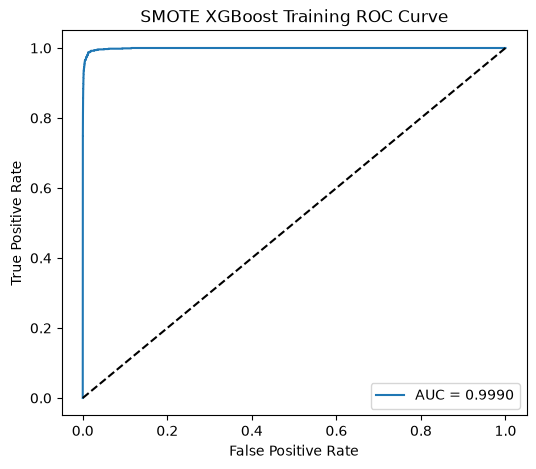

In [33]:
best_smote_xgb = smote_search.best_estimator_

smote_train_error = evaluate_model(
    best_smote_xgb,
    X_train,
    y_train,
    "SMOTE XGBoost Training"
)


SMOTE XGBoost Test
Confusion Matrix:
 [[15453   172]
 [   45   330]]
AUC: 0.993661
Misclassification Rate: 0.013563


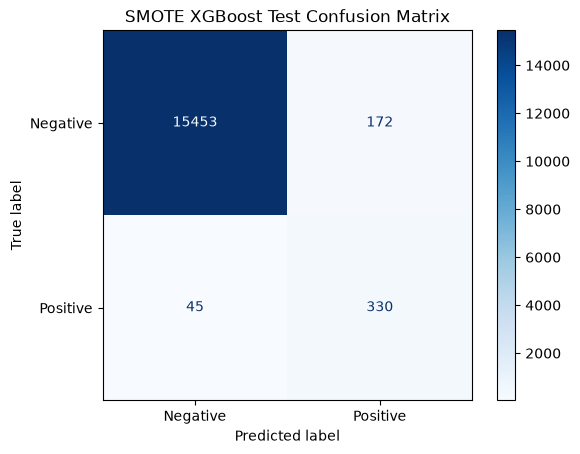

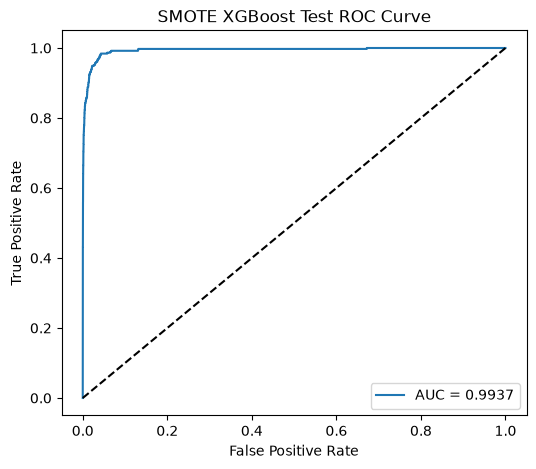

In [34]:
# The test set is already filled with its own medians,
# so the imputer inside the pipeline has nothing left to fill
smote_test_error = evaluate_model(
    best_smote_xgb,
    X_test_imputed,
    y_test,
    "SMOTE XGBoost Test"
)

In [35]:
smote_cv_error = 1 - smote_search.best_score_

print(f"SMOTE CV Error: {smote_cv_error:.6f}")
print(f"SMOTE Test Error: {smote_test_error:.6f}")
print(f"Difference: {abs(smote_cv_error - smote_test_error):.6f}")

SMOTE CV Error: 0.009200
SMOTE Test Error: 0.013563
Difference: 0.004363


In [36]:
# Compare XGBoost with and without SMOTE
xgb_smote_comparison = pd.DataFrame([
    {"Model": "XGBoost", "CV Error": xgb_cv_error,
     **test_summary(best_xgb, X_test_imputed, y_test)},
    {"Model": "SMOTE + XGBoost", "CV Error": smote_cv_error,
     **test_summary(best_smote_xgb, X_test_imputed, y_test)}
])

display(xgb_smote_comparison.round(6))

,Model,CV Error,Test Error,Test AUC,False Positives,False Negatives,Positive Recall,APS Cost
0,XGBoost,0.005667,0.006437,0.995553,15,88,0.765333,44150
1,SMOTE + XGBoost,0.009200,0.013563,0.993661,172,45,0.880000,24220


In [37]:
# Sensitivity check (extra comparison, not the main result):
# pass the raw X_test to the pipelines, so the test set is filled with TRAINING medians,
# i.e. the same rule that was used for the validation folds during CV
sensitivity = pd.DataFrame([
    {"Model": "XGBoost", "Test imputation": "test medians (main result)",
     "CV Error": xgb_cv_error, **test_summary(best_xgb, X_test_imputed, y_test)},
    {"Model": "XGBoost", "Test imputation": "training medians (check)",
     "CV Error": xgb_cv_error, **test_summary(best_xgb, X_test, y_test)},
    {"Model": "SMOTE + XGBoost", "Test imputation": "test medians (main result)",
     "CV Error": smote_cv_error, **test_summary(best_smote_xgb, X_test_imputed, y_test)},
    {"Model": "SMOTE + XGBoost", "Test imputation": "training medians (check)",
     "CV Error": smote_cv_error, **test_summary(best_smote_xgb, X_test, y_test)}
])

display(sensitivity.round(6))

,Model,Test imputation,CV Error,Test Error,Test AUC,False Positives,False Negatives,Positive Recall,APS Cost
0,XGBoost,test medians (main result),0.005667,0.006437,0.995553,15,88,0.765333,44150
1,XGBoost,training medians (check),0.005667,0.006437,0.995554,15,88,0.765333,44150
2,SMOTE + XGBoost,test medians (main result),0.009200,0.013563,0.993661,172,45,0.880000,24220
3,SMOTE + XGBoost,training medians (check),0.009200,0.009437,0.994267,103,48,0.872000,25030


**Right vs wrong way of cross-validation with SMOTE.** The wrong way is to run SMOTE on the whole training set first and then do CV. SMOTE creates new positives by interpolating between real positives, so the validation folds would contain points that are almost copies of points in the training folds, and the CV error would look too good. The right way is to apply SMOTE only to the training part of each fold and keep the validation fold untouched. I did this with an imbalanced-learn `Pipeline` (median imputation → SMOTE → XGBoost), so `GridSearchCV` refits imputation and SMOTE inside every fold. The final model is then trained on the full training set after SMOTE. Training metrics are computed on the original (non-synthetic) training data, and the test set is filled with its own medians as before.

**Choosing $\alpha$.** With the same 5-fold CV and the same grid, the best value was again $\alpha = 0.5$ (CV error 0.0092). As before, the differences between $\alpha$ values are very small.

| | Training | Test |
|---|---|---|
| Confusion matrix | [[58765, 235], [46, 954]] | [[15453, 172], [45, 330]] |
| AUC | 0.9990 | 0.9937 |
| Misclassification rate | 0.0047 | 0.0136 |

**Uncompensated vs SMOTE (test set):**

| | XGBoost | SMOTE + XGBoost |
|---|---|---|
| CV error | 0.0057 | 0.0092 |
| Test error | 0.0064 | 0.0136 |
| Test AUC | 0.9956 | 0.9937 |
| False positives | 15 | 172 |
| False negatives | 88 | 45 |
| Positive recall | 76.5% | 88.0% |
| APS cost (10·FP + 500·FN) | 44,150 | 24,220 |

SMOTE roughly halves the number of missed failures (88 → 45), but the number of false alarms grows by more than 10 times, so the overall error rate doubles. The AUC is slightly lower, so SMOTE does not really improve how the model ranks trucks; it mainly shifts the decision boundary toward the negative class. If plain accuracy is the goal, the uncompensated XGBoost is better. Under the APS cost, where a missed failure costs 50 times a false alarm, the SMOTE model is clearly cheaper.

**Why is the CV-vs-test gap larger for the SMOTE model?** Its CV error is 0.0092 but its test error is 0.0136. The two numbers are not computed in exactly the same way: inside CV the validation folds are filled with training medians, while the test set is filled with its own medians (footnote 1). To check how much this matters, I also ran both final models on the test set filled with training medians (the sensitivity table above). This is only an extra check; the results reported above stay the main ones.

| | Test imputation | Test error | Test AUC | FP | FN | Recall | APS cost |
|---|---|---|---|---|---|---|---|
| XGBoost | test medians (main) | 0.0064 | 0.9956 | 15 | 88 | 76.5% | 44,150 |
| XGBoost | training medians (check) | 0.0064 | 0.9956 | 15 | 88 | 76.5% | 44,150 |
| SMOTE + XGBoost | test medians (main) | 0.0136 | 0.9937 | 172 | 45 | 88.0% | 24,220 |
| SMOTE + XGBoost | training medians (check) | 0.0094 | 0.9943 | 103 | 48 | 87.2% | 25,030 |

The uncompensated XGBoost gives identical results under both rules, so it is not sensitive to how the test set is filled. The SMOTE model is: with training medians its test error drops to 0.0094, almost the same as its CV error (0.0092), and most of the extra false alarms disappear (172 → 103), while recall barely changes. So the larger gap for the SMOTE model comes mostly from the different imputation of the test set, not from the CV estimate being off. A plausible explanation is that SMOTE interpolates between real positives, many of which had missing values filled with training medians, so the model learns patterns around those exact values; when the test set uses slightly different medians, more negatives end up on the positive side of the boundary. The comparison between the two models does not change under either rule: SMOTE has the higher error but catches clearly more failures and has the lower APS cost.

## 2. ISLR Chapter 6, Exercise 3

### Question 2: Lasso with the constraint $\sum_j |\beta_j| \le s$

Here the lasso minimizes the RSS subject to $\sum_{j=1}^{p}|\beta_j| \le s$. At $s = 0$ all coefficients are forced to 0 (the null model). As $s$ grows the constraint gets looser, and once $s$ is large enough the solution is just least squares. So increasing $s$ means increasing flexibility.

**(a) Training RSS: iv. Steadily decrease.** A larger $s$ only enlarges the feasible set, so the minimized training RSS can never go up. It keeps going down until the least squares solution becomes feasible, and stays flat after that.

**(b) Test RSS: ii. Decrease initially, and then eventually start increasing in a U shape.** At first, letting the coefficients move away from 0 removes a lot of bias and the test RSS drops. When $s$ gets large the model starts fitting noise, and the added variance pushes the test RSS back up.

**(c) Variance: iii. Steadily increase.** At $s = 0$ the fit is a constant and has essentially no variance. Relaxing the constraint lets the coefficients react more to the particular training sample, so the variance goes up.

**(d) Squared bias: iv. Steadily decrease.** The null model has the largest bias. As the constraint is relaxed, the model can get closer to the true relationship, so the squared bias goes down.

**(e) Irreducible error: v. Remain constant.** The irreducible error $\mathrm{Var}(\epsilon)$ comes from the noise in the data, not from the model, so it does not depend on $s$.

## 3. ISLR Chapter 6, Exercise 5

### Question 3: Ridge and lasso with two identical predictors

$n = 2$, $p = 2$, $x_{11} = x_{12}$, $x_{21} = x_{22}$, and since everything is centered, $\hat\beta_0 = 0$.

**(a) Ridge optimization problem**

$$
\min_{\beta_1,\beta_2}\;
\sum_{i=1}^{2}(y_i-\beta_1x_{i1}-\beta_2x_{i2})^2
+\lambda(\beta_1^2+\beta_2^2).
$$

Because $x_{i1} = x_{i2}$, this is the same as

$$
\min_{\beta_1,\beta_2}\;
\big(y_1-x_{11}(\beta_1+\beta_2)\big)^2
+\big(y_2-x_{21}(\beta_1+\beta_2)\big)^2
+\lambda(\beta_1^2+\beta_2^2).
$$

**(b) The ridge estimates satisfy $\hat\beta_1 = \hat\beta_2$**

Setting the partial derivatives to zero:

$$
\frac{\partial}{\partial\beta_1}:\;
-2\sum_{i=1}^{2}x_{i1}\big(y_i-\beta_1x_{i1}-\beta_2x_{i2}\big)+2\lambda\beta_1=0,
$$

$$
\frac{\partial}{\partial\beta_2}:\;
-2\sum_{i=1}^{2}x_{i2}\big(y_i-\beta_1x_{i1}-\beta_2x_{i2}\big)+2\lambda\beta_2=0.
$$

Since $x_{i2} = x_{i1}$, the sums in the two equations are identical. Subtracting one equation from the other leaves

$$
2\lambda(\beta_1-\beta_2)=0,
$$

so for $\lambda > 0$ we get $\hat\beta_1 = \hat\beta_2$. For $\lambda > 0$ the ridge objective is strictly convex, so this stationary point is the unique minimizer.

**(c) Lasso optimization problem**

$$
\min_{\beta_1,\beta_2}\;
\sum_{i=1}^{2}(y_i-\beta_1x_{i1}-\beta_2x_{i2})^2
+\lambda(|\beta_1|+|\beta_2|)
$$

which, using $x_{i1} = x_{i2}$, becomes

$$
\min_{\beta_1,\beta_2}\;
\big(y_1-x_{11}(\beta_1+\beta_2)\big)^2
+\big(y_2-x_{21}(\beta_1+\beta_2)\big)^2
+\lambda(|\beta_1|+|\beta_2|).
$$

**(d) The lasso coefficients are not unique**

Let $t = \beta_1 + \beta_2$. The RSS part depends only on $t$. For the penalty, the triangle inequality gives

$$
|\beta_1|+|\beta_2| \ge |\beta_1+\beta_2| = |t|,
$$

with equality exactly when $\beta_1$ and $\beta_2$ have the same sign (or one of them is 0). So for a fixed $t$, the objective is smallest, and equal to $\mathrm{RSS}(t) + \lambda|t|$, for every pair with $\beta_1 + \beta_2 = t$ and matching signs.

Let $\hat t$ be the optimal value of $t$. If $\hat t > 0$, every pair

$$
\hat\beta_1 = a,\qquad \hat\beta_2 = \hat t - a,\qquad 0 \le a \le \hat t
$$

gives the same minimum value of the objective (and similarly with both coefficients $\le 0$ if $\hat t < 0$). So there are infinitely many lasso solutions: the solution set is a line segment rather than a single point. The only exception is $\hat t = 0$, where the unique solution is $(0, 0)$.

## 4. ISLR Chapter 8, Exercise 5

### Question 4: Combining bagged classification trees

The 10 estimates of $P(\text{Red} \mid X)$ are

$$
0.1,\ 0.15,\ 0.2,\ 0.2,\ 0.55,\ 0.6,\ 0.6,\ 0.65,\ 0.7,\ 0.75.
$$

**Majority vote.** A tree votes Red if its probability is above 0.5. Six trees (0.55, 0.6, 0.6, 0.65, 0.7, 0.75) vote Red and four vote Green, so the majority vote gives **Red**.

**Average probability.**

$$
\bar p=\frac{0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75}{10}=\frac{4.5}{10}=0.45 < 0.5,
$$

so this approach gives **Green**.

The two methods disagree. More trees lean slightly toward Red, but the four Green trees are very confident (probabilities of 0.1–0.2), and they pull the average below 0.5.

## 5. ISLR Chapter 9, Exercise 3

### 5(a) Sketch the Observations

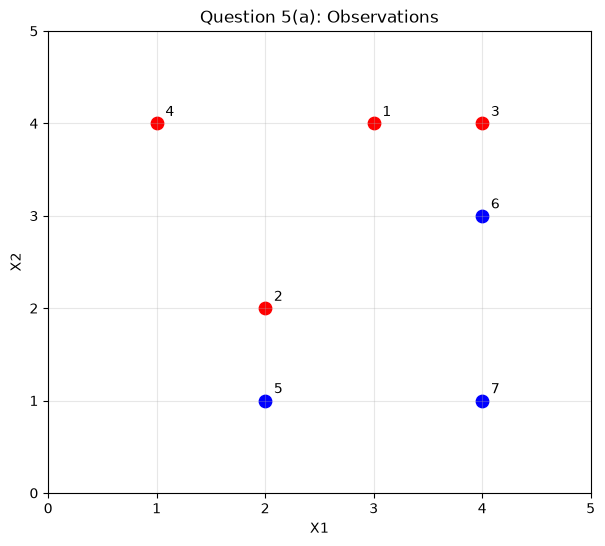

In [38]:
red_points = [(3, 4), (2, 2), (4, 4), (1, 4)]
blue_points = [(2, 1), (4, 3), (4, 1)]

plt.figure(figsize=(7, 6))

for i, (x, y) in enumerate(red_points, 1):
    plt.scatter(x, y, color="red", s=80)
    plt.annotate(str(i), (x+0.08, y+0.08))

for i, (x, y) in enumerate(blue_points, 5):
    plt.scatter(x, y, color="blue", s=80)
    plt.annotate(str(i), (x+0.08, y+0.08))

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Question 5(a): Observations")
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.grid(True, alpha=0.3)
plt.show()

### 5(b) Optimal Separating Hyperplane

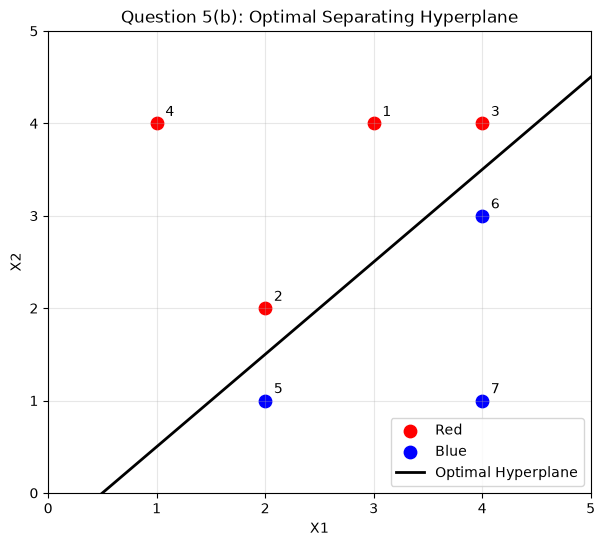

In [39]:
plt.figure(figsize=(7, 6))

for i, (x, y) in enumerate(red_points, 1):
    plt.scatter(x, y, color="red", s=80,
                label="Red" if i == 1 else "")
    plt.annotate(str(i), (x+0.08, y+0.08))

for i, (x, y) in enumerate(blue_points, 5):
    plt.scatter(x, y, color="blue", s=80,
                label="Blue" if i == 5 else "")
    plt.annotate(str(i), (x+0.08, y+0.08))

# Optimal separating hyperplane
x_values = np.linspace(0, 5, 100)
y_values = x_values - 0.5

plt.plot(
    x_values,
    y_values,
    "k-",
    linewidth=2,
    label="Optimal Hyperplane"
)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Question 5(b): Optimal Separating Hyperplane")
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

The red points closest to the blue class are (2, 2) and (4, 4), and both lie on the line $X_2 = X_1$. The blue points closest to the red class are (2, 1) and (4, 3), and both lie on the parallel line $X_2 = X_1 - 1$. All other red points are above $X_2 = X_1$, all other blue points are below $X_2 = X_1 - 1$, and there are no observations between the two lines. These two parallel lines are the boundaries of the widest gap between the classes, so the maximal margin hyperplane is the line halfway between them, which passes through the midpoints (2, 1.5) and (4, 3.5):

$$
X_2 = X_1 - 0.5 \quad\Longleftrightarrow\quad X_1 - X_2 - 0.5 = 0.
$$

All red points are above this line and all blue points are below it.

### 5(c) Classification Rule

Writing the hyperplane as $\beta_0 + \beta_1X_1 + \beta_2X_2 = 0$:

$$
0.5 - X_1 + X_2 = 0, \qquad \beta_0 = 0.5,\ \beta_1 = -1,\ \beta_2 = 1.
$$

Classify to **Red** if $0.5 - X_1 + X_2 > 0$, and to **Blue** otherwise (i.e. if $0.5 - X_1 + X_2 < 0$).

### 5(d) Margin of the Maximal Margin Classifier

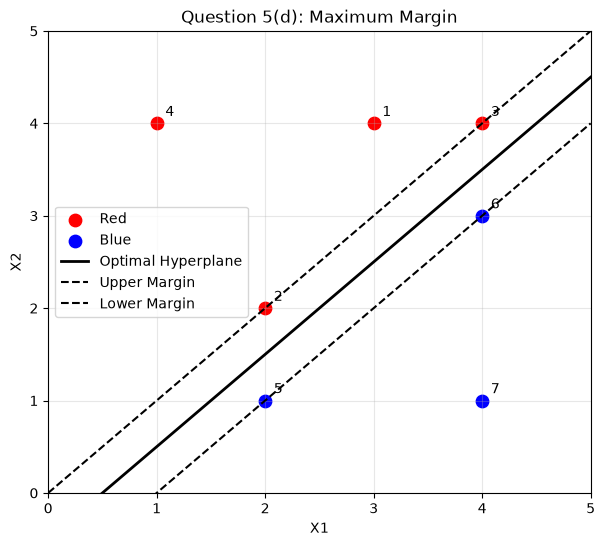

In [40]:
plt.figure(figsize=(7, 6))

for i, (x, y) in enumerate(red_points, 1):
    plt.scatter(x, y, color="red", s=80,
                label="Red" if i == 1 else "")
    plt.annotate(str(i), (x+0.08, y+0.08))

for i, (x, y) in enumerate(blue_points, 5):
    plt.scatter(x, y, color="blue", s=80,
                label="Blue" if i == 5 else "")
    plt.annotate(str(i), (x+0.08, y+0.08))

x_values = np.linspace(0, 5, 100)

# Optimal hyperplane
plt.plot(
    x_values, x_values - 0.5,
    "k-", linewidth=2, label="Optimal Hyperplane"
)

# Margin boundaries
plt.plot(
    x_values, x_values,
    "k--", label="Upper Margin"
)

plt.plot(
    x_values, x_values - 1,
    "k--", label="Lower Margin"
)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Question 5(d): Maximum Margin")
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

The margin boundaries are the two parallel lines through the support vectors:

$$
X_2 = X_1 \quad\text{(red side)}, \qquad X_2 = X_1 - 1 \quad\text{(blue side)}.
$$

The margin is the distance from the hyperplane to either boundary, e.g. from (2, 2) to $X_1 - X_2 - 0.5 = 0$:

$$
M=\frac{|2-2-0.5|}{\sqrt{1^2+(-1)^2}}=\frac{0.5}{\sqrt2}\approx 0.354.
$$

So the margin is about 0.354, and the total width between the two dashed lines is about 0.707.

### 5(e) Support Vectors

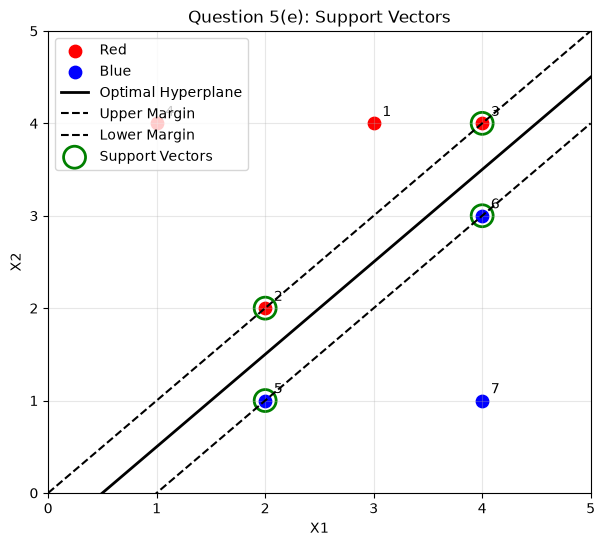

In [41]:
plt.figure(figsize=(7, 6))

for i, (x, y) in enumerate(red_points, 1):
    plt.scatter(x, y, color="red", s=80,
                label="Red" if i == 1 else "")
    plt.annotate(str(i), (x+0.08, y+0.08))

for i, (x, y) in enumerate(blue_points, 5):
    plt.scatter(x, y, color="blue", s=80,
                label="Blue" if i == 5 else "")
    plt.annotate(str(i), (x+0.08, y+0.08))

x_values = np.linspace(0, 5, 100)

# Decision boundary
plt.plot(x_values, x_values - 0.5,
         "k-", linewidth=2, label="Optimal Hyperplane")

# Margin boundaries
plt.plot(x_values, x_values,
         "k--", label="Upper Margin")
plt.plot(x_values, x_values - 1,
         "k--", label="Lower Margin")

# Highlight support vectors
support_vectors = [(2, 2), (4, 4), (2, 1), (4, 3)]

for i, (x, y) in enumerate(support_vectors):
    plt.scatter(
        x, y,
        s=250,
        facecolors="none",
        edgecolors="green",
        linewidths=2,
        label="Support Vectors" if i == 0 else ""
    )

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Question 5(e): Support Vectors")
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

The support vectors are the points lying on the margin boundaries:

- Observation 2: (2, 2), Red and Observation 3: (4, 4), Red, on $X_2 = X_1$
- Observation 5: (2, 1), Blue and Observation 6: (4, 3), Blue, on $X_2 = X_1 - 1$

These four points alone determine the hyperplane.

### 5(f) Effect of Moving Observation 7

Observation 7 is (4, 1). Its distance to the hyperplane is $|4 - 1 - 0.5|/\sqrt2 \approx 1.77$, far outside the margin (0.354), and it is not a support vector. The maximal margin hyperplane depends only on the support vectors, so moving observation 7 slightly (as long as it doesn't move into the margin) does not change the hyperplane.

### 5(g) Non-Optimal Separating Hyperplane

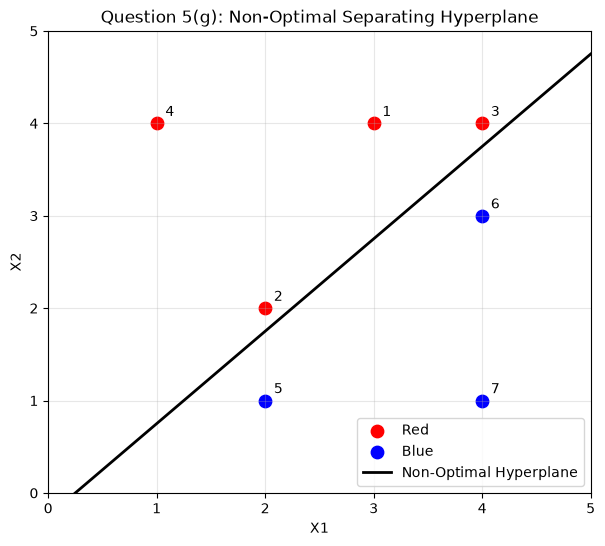

In [42]:
plt.figure(figsize=(7, 6))

for i, (x, y) in enumerate(red_points, 1):
    plt.scatter(x, y, color="red", s=80,
                label="Red" if i == 1 else "")
    plt.annotate(str(i), (x+0.08, y+0.08))

for i, (x, y) in enumerate(blue_points, 5):
    plt.scatter(x, y, color="blue", s=80,
                label="Blue" if i == 5 else "")
    plt.annotate(str(i), (x+0.08, y+0.08))

x_values = np.linspace(0, 5, 100)

plt.plot(
    x_values, x_values - 0.25,
    "k-", linewidth=2,
    label="Non-Optimal Hyperplane"
)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Question 5(g): Non-Optimal Separating Hyperplane")
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

The line

$$
X_2 = X_1 - 0.25 \quad\Longleftrightarrow\quad 0.25 - X_1 + X_2 = 0
$$

still separates the two classes, but it is not optimal. It is closer to the red points: its distance to (2, 2) and (4, 4) is $0.25/\sqrt2 \approx 0.177$, while the blue support vectors are $0.75/\sqrt2 \approx 0.530$ away. Its margin is therefore 0.177, about half of the maximal margin of 0.354 from part (d).

### 5(h) Non-Linearly Separable Data

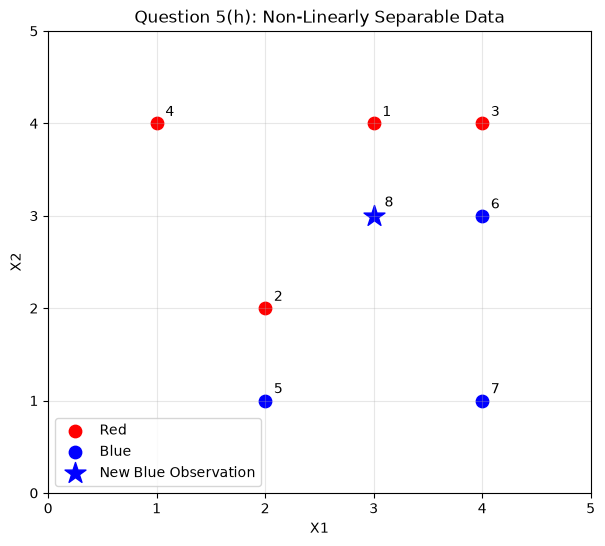

In [43]:
plt.figure(figsize=(7, 6))

for i, (x, y) in enumerate(red_points, 1):
    plt.scatter(x, y, color="red", s=80,
                label="Red" if i == 1 else "")
    plt.annotate(str(i), (x+0.08, y+0.08))

for i, (x, y) in enumerate(blue_points, 5):
    plt.scatter(x, y, color="blue", s=80,
                label="Blue" if i == 5 else "")
    plt.annotate(str(i), (x+0.08, y+0.08))

# Add a new Blue observation
plt.scatter(
    3, 3,
    color="blue",
    marker="*",
    s=250,
    label="New Blue Observation"
)

plt.annotate("8", (3.1, 3.1))

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Question 5(h): Non-Linearly Separable Data")
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

I added a blue observation at (3, 3) (observation 8 in the plot).

This point is the midpoint of the red observations (2, 2) and (4, 4). Any line that puts (2, 2) and (4, 4) on the red side also puts every point of the segment between them on the red side, so (3, 3) can never be on the blue side. The two classes are therefore no longer separable by a hyperplane, and a maximal margin classifier does not exist for this data.